# Selecting the best model with Best hyperparameters: Diabetes Dataset

Same steps as the `Decision_Tree.ipynb` class notebook (tips dataset), now on the **diabetes** dataset:
1. Train many models with default settings and compare them
2. Hyperparameter tuning with `GridSearchCV`
3. **Assignment solution:** get the best parameters of every model inside the for loop, and get the best model out of it

**What is different from the tips (regression) notebook**
- `diabetes` is **classification** (0 = No, 1 = Yes), so we use the `...Classifier` models and classification metrics (Accuracy, Precision, Recall, F1, ROC-AUC) instead of MSE / MAE / R2.
- Only ~9% of patients are diabetic (**imbalanced**). A model that always says "No" gets 91% accuracy, so **accuracy is not a good metric here**. We use **F1** and **ROC-AUC** to choose the best model.
- The data is already encoded and scaled (`diabetes_after_preprocessing.csv`), so no `LabelEncoder` is needed.

### Import libraries

In [1]:
# import libraries
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

# train test split the data (stratify keeps the same 9% diabetic ratio in train and test)
from sklearn.model_selection import train_test_split, StratifiedKFold

# import grid search cv for cross validation
from sklearn.model_selection import GridSearchCV

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# classification metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.base import clone

### Load dataset

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
df.head()

,age,bmi,hba1c_level,blood_glucose_level,hypertension,heart_disease,gender_male,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_unknown,diabetes
0,1.701773,-0.310755,0.994239,0.043415,0,1,0.0,0.0,0.0,1.0,0.0,0
1,0.544112,0.048864,0.994239,-1.422971,0,0,0.0,0.0,0.0,0.0,1.0,0
2,-0.613548,0.048864,0.155650,0.483331,0,0,1.0,0.0,0.0,1.0,0.0,0
3,-0.257345,-0.604528,-0.496585,0.410012,0,0,0.0,0.0,0.0,0.0,0.0,0
4,1.523671,-1.163373,-0.682938,0.410012,1,1,1.0,0.0,0.0,0.0,0.0,0


In [3]:
df.columns

Index(['age', 'bmi', 'hba1c_level', 'blood_glucose_level', 'hypertension',
       'heart_disease', 'gender_male', 'smoking_history_ever',
       'smoking_history_former', 'smoking_history_never',
       'smoking_history_unknown', 'diabetes'],
      dtype='str')

In [4]:
# how imbalanced is the target?
print(df['diabetes'].value_counts())
print((df['diabetes'].value_counts(normalize=True) * 100).round(1).astype(str) + ' %')

diabetes
0    87548
1     8482
Name: count, dtype: int64
diabetes
0    91.2 %
1     8.8 %
Name: proportion, dtype: str


## Classification Tasks

In [5]:
# select features and variables
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# split the data into train and test data with 80% training dataset (stratified because of the imbalance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(76824, 11) (19206, 11)


### 1. All models with default settings
A helper function gives every metric for a fitted model. `SVC` has no `predict_proba` by default, so for ROC-AUC we use its `decision_function` score instead.

In [6]:
def get_scores(model, X_test, y_test):
    # make prediction from the model
    y_pred = model.predict(X_test)

    # score for ROC-AUC (probability if the model has it, else decision score)
    if hasattr(model, 'predict_proba'):
        score = model.predict_proba(X_test)[:, 1]
    else:
        score = model.decision_function(X_test)

    return {'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC_AUC': roc_auc_score(y_test, score)}

In [ ]:
%%time
# Create a dictionaries of list of models to evaluate performance
models = {
          'LogisticRegression' : LogisticRegression(max_iter=1000),
          'SVC' : SVC(),
          'DecisionTreeClassifier' : DecisionTreeClassifier(random_state=42),
          'RandomForestClassifier' : RandomForestClassifier(random_state=42),
          'KNeighborsClassifier' : KNeighborsClassifier(),
          'GradientBoostingClassifier' : GradientBoostingClassifier(random_state=42),
          'XGBClassifier' : XGBClassifier(random_state=42, verbosity=0)
          }

# train and predict each model with evaluation metrics as well making a for loop to iterate over the models
model_scores = []
for name, model in models.items():
    # fit each model from models on training data
    model.fit(X_train, y_train)

    # evaluate on the test data
    scores = get_scores(model, X_test, y_test)
    scores['Model'] = name
    model_scores.append(scores)

Best model for **each metric** (sorted):

In [ ]:
default_df = pd.DataFrame(model_scores).set_index('Model')

# selecting the best model from all above models with each evaluation metric (higher is better for all)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']:
    print(f'--- {metric} ---')
    for name, value in default_df[metric].sort_values(ascending=False).items():
        print(f'{metric} of {name} is {value: .3f}')
    print()

--- Accuracy ---
Accuracy of GradientBoostingClassifier is  0.971
Accuracy of XGBClassifier is  0.970
Accuracy of RandomForestClassifier is  0.969
Accuracy of SVC is  0.965
Accuracy of KNeighborsClassifier is  0.959
Accuracy of LogisticRegression is  0.958
Accuracy of DecisionTreeClassifier is  0.949

--- Precision ---
Precision of SVC is  0.989
Precision of GradientBoostingClassifier is  0.983
Precision of XGBClassifier is  0.954
Precision of RandomForestClassifier is  0.931
Precision of KNeighborsClassifier is  0.884
Precision of LogisticRegression is  0.862
Precision of DecisionTreeClassifier is  0.697

--- Recall ---
Recall of DecisionTreeClassifier is  0.740
Recall of RandomForestClassifier is  0.696
Recall of XGBClassifier is  0.690
Recall of GradientBoostingClassifier is  0.685
Recall of LogisticRegression is  0.626
Recall of KNeighborsClassifier is  0.623
Recall of SVC is  0.607

--- F1 ---
F1 of GradientBoostingClassifier is  0.807
F1 of XGBClassifier is  0.801
F1 of RandomFor

**Why the best model changes with the metric:**
- Models like `SVC`, `KNN` and `LogisticRegression` have very high **precision** but low **recall** (they say "diabetic" only when very sure, so they miss many patients).
- Look at **F1** (balance of both) and **ROC-AUC** (quality of the ranking) to choose, not accuracy.

In [ ]:
default_df.round(3).sort_values('F1', ascending=False)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
GradientBoostingClassifier,0.971,0.983,0.685,0.807,0.977
XGBClassifier,0.970,0.954,0.690,0.801,0.976
RandomForestClassifier,0.969,0.931,0.696,0.796,0.962
SVC,0.965,0.989,0.607,0.753,0.932
KNeighborsClassifier,0.959,0.884,0.623,0.731,0.904
LogisticRegression,0.958,0.862,0.626,0.725,0.959
DecisionTreeClassifier,0.949,0.697,0.740,0.718,0.854


## Assignment: Find the best model based on each metric from the above results
Answer from the table above: pick the first model in each sorted list. The code below does it automatically.

In [ ]:
best_per_metric = pd.DataFrame({'Best model': default_df.idxmax(), 'Score': default_df.max()})
best_per_metric.round(3)

,Best model,Score
Accuracy,GradientBoostingClassifier,0.971
Precision,SVC,0.989
Recall,DecisionTreeClassifier,0.740
F1,GradientBoostingClassifier,0.807
ROC_AUC,GradientBoostingClassifier,0.977


---
# Hyperparameter tuning

### Speed trick
`GridSearchCV` tries every parameter combination x 5 folds, and `SVC` / `KNN` are slow on 77,000 rows. So the **search runs on a stratified sample of 20,000 rows**, then every model is **trained again on the full training data** with its best parameters and tested on the test data.

Models are tuned by **F1** (a balanced metric for imbalanced data). ROC-AUC is also recorded.

`class_weight='balanced'` (and `scale_pos_weight` for XGBoost) gives more weight to the rare diabetic class; it is part of the grid, so `GridSearchCV` decides if it helps.

In [ ]:
# stratified sample of 20,000 rows used only for the search
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=20000, random_state=0, stratify=y_train)
print(X_tune.shape, '| Diabetic %:', round(y_tune.mean() * 100, 2))

# stratified 5-fold cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(20000, 11) | Diabetic %: 8.83


In [ ]:
# Create a dictionaries of list of models to evaluate performance with hyperparameters
models = {
          'LogisticRegression' : (LogisticRegression(max_iter=1000),
                                  {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']}),

          'SVC' : (SVC(kernel='rbf'),
                   {'C': [0.1, 1, 10], 'gamma': [0.003, 0.01], 'class_weight': [None, 'balanced']}),

          'DecisionTreeClassifier' : (DecisionTreeClassifier(random_state=42),
                                      {'max_depth': [3, 5, 7, 10, None], 'min_samples_leaf': [1, 10, 50],
                                       'class_weight': [None, 'balanced']}),

          'RandomForestClassifier' : (RandomForestClassifier(random_state=42),
                                      {'n_estimators': [100, 300], 'max_depth': [10, None],
                                       'class_weight': [None, 'balanced']}),

          'KNeighborsClassifier' : (KNeighborsClassifier(algorithm='kd_tree'),
                                    {'n_neighbors': [5, 11, 21, 51], 'weights': ['uniform', 'distance']}),

          'GradientBoostingClassifier' : (GradientBoostingClassifier(random_state=42),
                                          {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1],
                                           'max_depth': [2, 3]}),

          'XGBClassifier' : (XGBClassifier(random_state=42, verbosity=0),
                             {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5],
                              'scale_pos_weight': [1, 10]}),
          }
print(len(models), 'models to tune')

7 models to tune


## Assignment: How to get the best parameters of each model (inside the for loop) and the best model out of it?
## Solution

In [ ]:
%%time
# Write your Code here
# For every model: GridSearchCV -> best parameters -> train again on full train data -> test scores

tuned_models = {}      # best model of each algorithm
best_params = {}       # best parameters of each algorithm
tuning_rows = []

for name, (model, params) in models.items():
    t0 = time.time()

    # create the grid search (scoring F1, also record ROC-AUC)
    grid = GridSearchCV(model, params, cv=cv, scoring={'f1': 'f1', 'roc_auc': 'roc_auc'},
                        refit='f1', n_jobs=-1)

    # fit the grid search on the tuning sample
    grid.fit(X_tune, y_tune)

    # ---- best parameters of this model ----
    best_params[name] = grid.best_params_

    # train the best model again on the FULL training data, then predict the test data
    best_model = clone(grid.best_estimator_).fit(X_train, y_train)
    tuned_models[name] = best_model

    scores = get_scores(best_model, X_test, y_test)
    tuning_rows.append({'Model': name, 'CV_F1': grid.best_score_,
                        'CV_ROC_AUC': grid.cv_results_['mean_test_roc_auc'][grid.best_index_],
                        **{f'Test_{k}': v for k, v in scores.items()}, 'Best_Params': grid.best_params_})

    # print the performing metric and the best parameters
    print(name, '| CV F1:', round(grid.best_score_, 4), '| Test F1:', round(scores['F1'], 4),
          '| Test ROC_AUC:', round(scores['ROC_AUC'], 4), f'| {time.time() - t0:.0f}s')
    print('   Best params:', grid.best_params_, '\n')

LogisticRegression | CV F1: 0.7332 | Test F1: 0.725 | Test ROC_AUC: 0.9593 | 1s
   Best params: {'C': 1, 'class_weight': None} 



SVC | CV F1: 0.7259 | Test F1: 0.7255 | Test ROC_AUC: 0.9151 | 191s
   Best params: {'C': 10, 'class_weight': None, 'gamma': 0.01} 



DecisionTreeClassifier | CV F1: 0.8103 | Test F1: 0.8048 | Test ROC_AUC: 0.9682 | 5s
   Best params: {'class_weight': None, 'max_depth': 7, 'min_samples_leaf': 10} 



RandomForestClassifier | CV F1: 0.808 | Test F1: 0.8037 | Test ROC_AUC: 0.9723 | 80s
   Best params: {'class_weight': None, 'max_depth': 10, 'n_estimators': 300} 



KNeighborsClassifier | CV F1: 0.7164 | Test F1: 0.7305 | Test ROC_AUC: 0.9044 | 17s
   Best params: {'n_neighbors': 5, 'weights': 'uniform'} 



GradientBoostingClassifier | CV F1: 0.8134 | Test F1: 0.8057 | Test ROC_AUC: 0.9774 | 98s
   Best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300} 



XGBClassifier | CV F1: 0.8118 | Test F1: 0.8035 | Test ROC_AUC: 0.9769 | 16s
   Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': 1} 

CPU times: user 6min 44s, sys: 429 ms, total: 6min 45s
Wall time: 6min 49s


### Best parameters of every model

In [ ]:
for name, p in best_params.items():
    print(f'{name:<28}', p)

LogisticRegression           {'C': 1, 'class_weight': None}
SVC                          {'C': 10, 'class_weight': None, 'gamma': 0.01}
DecisionTreeClassifier       {'class_weight': None, 'max_depth': 7, 'min_samples_leaf': 10}
RandomForestClassifier       {'class_weight': None, 'max_depth': 10, 'n_estimators': 300}
KNeighborsClassifier         {'n_neighbors': 5, 'weights': 'uniform'}
GradientBoostingClassifier   {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}
XGBClassifier                {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': 1}


### Best model out of all models
The best model is chosen by **CV F1** (cross-validation on the training sample), not by the test data.

In [ ]:
tuning_df = pd.DataFrame(tuning_rows).sort_values('CV_F1', ascending=False).reset_index(drop=True)
tuning_df.index = tuning_df.index + 1
tuning_df.index.name = 'Rank'
display(tuning_df.drop(columns='Best_Params').round(4))

best_name = tuning_df.iloc[0]['Model']
best_model = tuned_models[best_name]
print('Best model      :', best_name)
print('Best parameters :', best_params[best_name])
print('Test F1         :', round(tuning_df.iloc[0]['Test_F1'], 4))
print('Test ROC_AUC    :', round(tuning_df.iloc[0]['Test_ROC_AUC'], 4))

,Model,CV_F1,CV_ROC_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
Rank,,,,,,,,
1,GradientBoostingClassifier,0.8134,0.9788,0.9709,0.9814,0.6834,0.8057,0.9774
2,XGBClassifier,0.8118,0.9785,0.9708,0.9922,0.6751,0.8035,0.9769
3,DecisionTreeClassifier,0.8103,0.9672,0.9712,1.0000,0.6733,0.8048,0.9682
4,RandomForestClassifier,0.8080,0.9729,0.9709,0.9965,0.6733,0.8037,0.9723
5,LogisticRegression,0.7332,0.9623,0.9581,0.8619,0.6256,0.7250,0.9593
6,SVC,0.7259,0.9342,0.9614,0.9761,0.5772,0.7255,0.9151
7,KNeighborsClassifier,0.7164,0.8996,0.9594,0.8837,0.6226,0.7305,0.9044


Best model      : GradientBoostingClassifier
Best parameters : {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}
Test F1         : 0.8057
Test ROC_AUC    : 0.9774


### Default vs tuned (Test F1)
Did tuning help?

In [ ]:
cmp = pd.DataFrame({'Default F1': default_df['F1'],
                    'Tuned F1': tuning_df.set_index('Model')['Test_F1']})
cmp['Change'] = cmp['Tuned F1'] - cmp['Default F1']
cmp.round(3).sort_values('Tuned F1', ascending=False)

,Default F1,Tuned F1,Change
Model,,,
GradientBoostingClassifier,0.807,0.806,-0.001
DecisionTreeClassifier,0.718,0.805,0.087
RandomForestClassifier,0.796,0.804,0.007
XGBClassifier,0.801,0.804,0.002
KNeighborsClassifier,0.731,0.731,0.000
LogisticRegression,0.725,0.725,0.000
SVC,0.753,0.725,-0.027


### Visualization

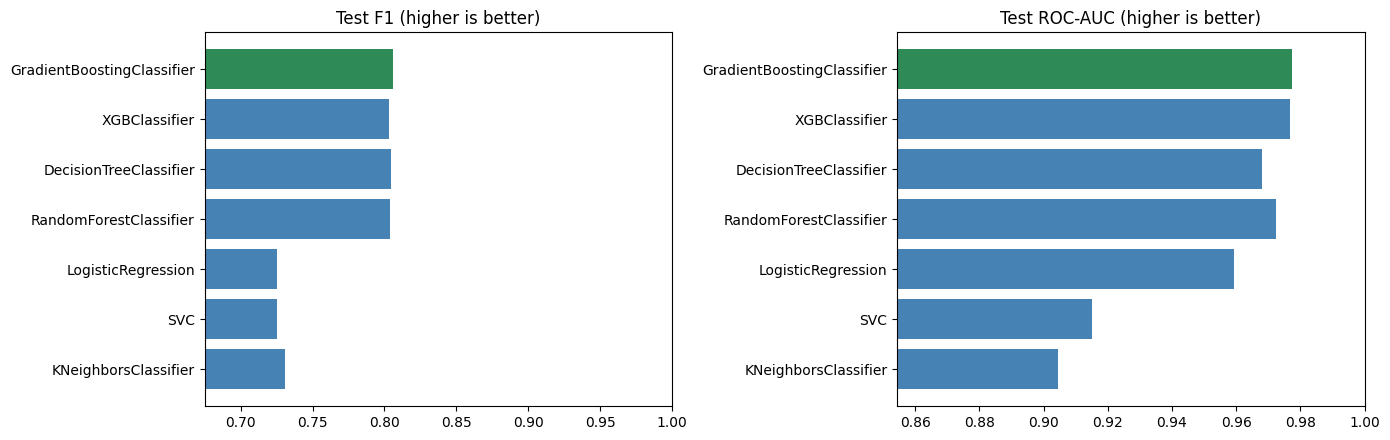

In [ ]:
order = tuning_df['Model']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

for a, metric, title in [(ax[0], 'Test_F1', 'Test F1 (higher is better)'), (ax[1], 'Test_ROC_AUC', 'Test ROC-AUC (higher is better)')]:
    vals = tuning_df.set_index('Model').loc[order, metric]
    a.barh(vals.index, vals.values, color=['seagreen' if m == best_name else 'steelblue' for m in vals.index])
    a.invert_yaxis(); a.set_title(title); a.set_xlim(vals.min() - 0.05, 1)
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

 No diabetes       0.97      1.00      0.98     17510
    Diabetes       0.98      0.68      0.81      1696

    accuracy                           0.97     19206
   macro avg       0.98      0.84      0.89     19206
weighted avg       0.97      0.97      0.97     19206



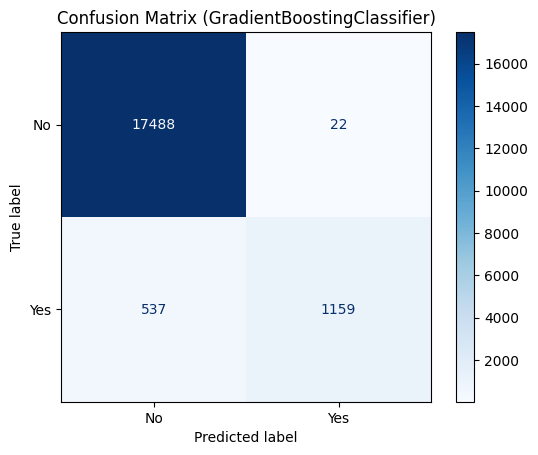

In [ ]:
# detailed report of the best model
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No', 'Yes'], cmap='Blues')
plt.title(f'Confusion Matrix ({best_name})'); plt.show()

### Save the best model (.pkl)
The best model (with its best parameters) is trained once more on all data, then saved.

In [ ]:
final_model = clone(best_model).fit(X, y)
joblib.dump({'model': final_model, 'name': best_name, 'params': best_params[best_name], 'features': list(X.columns)},
            'best_diabetes_model.pkl', compress=3)
tuning_df.to_csv('diabetes_model_selection_results.csv')
print('Saved: best_diabetes_model.pkl, diabetes_model_selection_results.csv')

Saved: best_diabetes_model.pkl, diabetes_model_selection_results.csv


### Download (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('best_diabetes_model.pkl')
    files.download('diabetes_model_selection_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
